# 04 - Perbandingan Tiga Model

Ketiga model memakai fitur dan split yang sama dari `build_features`
(tanpa `volume_hub_hari`). Test tidak dibuat, diprediksi, atau dievaluasi.

Ada satu ablasi kecil dengan `volume_hub_hari` hanya sebagai perbandingan;
model itu diberi label "leaky, not deployed" dan tidak dipilih.

In [1]:
from pathlib import Path
import json
import sys
import time

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import (
    FEATURE_COLUMNS_V1,
    build_features,
    make_logistic_preprocessor,
    tambah_volume_lag,
)

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

semua = pd.read_csv(ROOT / "data" / "clean.csv", parse_dates=["tanggal_pickup"])
train = semua.loc[semua["tanggal_pickup"] <= "2025-12-31"].copy()
valid = semua.loc[semua["tanggal_pickup"].between("2026-01-01", "2026-03-31")].copy()
del semua

referensi = pd.concat([train, valid], ignore_index=True)
train = tambah_volume_lag(train, referensi)
valid = tambah_volume_lag(valid, referensi)

assert valid["tanggal_pickup"].max() <= pd.Timestamp("2026-03-31")
print("Train:", len(train), "| Validation:", len(valid))

X_train = build_features(train)
X_valid = build_features(valid)
y_train = train["terlambat"]
y_valid = valid["terlambat"]

preprocessor = make_logistic_preprocessor()
X_train_t = preprocessor.fit_transform(X_train)
X_valid_t = preprocessor.transform(X_valid)
print("Fitur:", X_train.shape[1], "| setelah preprocessing:", X_train_t.shape[1])

Train: 26633 | Validation: 6623


Fitur: 20 | setelah preprocessing: 44


## Tuning ringan pada validation

Grid kecil. LightGBM memakai early stopping hanya untuk mencari jumlah boosted
trees terbaik; setelah itu model final di-fit ulang tanpa early stopping dengan
`n_estimators` yang sudah dikunci.

In [2]:
RANDOM_STATE = 42
rasio_kelas = float((y_train == 0).sum() / (y_train == 1).sum())
urutan = ["Logistic Regression", "Random Forest", "LightGBM"]


def coba_model(nama, estimator, parameter, pakai_early_stopping=False):
    model = clone(estimator).set_params(**parameter)
    mulai = time.perf_counter()
    if pakai_early_stopping:
        model.fit(
            X_train_t,
            y_train,
            eval_X=X_valid_t,
            eval_y=y_valid,
            eval_metric="average_precision",
            callbacks=[lgb.early_stopping(30, verbose=False)],
        )
    else:
        model.fit(X_train_t, y_train)
    durasi = time.perf_counter() - mulai
    proba = model.predict_proba(X_valid_t)[:, 1]
    return {
        "nama": nama,
        "param": parameter,
        "pr_auc": average_precision_score(y_valid, proba),
        "roc_auc": roc_auc_score(y_valid, proba),
        "detik": durasi,
        "model": model,
        "proba": proba,
    }


grid_logistik = {"C": [0.1, 1.0, 10.0], "class_weight": [None, "balanced"]}
grid_rf = {
    "n_estimators": [200],
    "min_samples_leaf": [1, 5],
    "class_weight": [None, "balanced_subsample"],
}
grid_lgb = {
    "n_estimators": [500],
    "learning_rate": [0.03, 0.1],
    "num_leaves": [15, 31],
    "scale_pos_weight": [1, round(rasio_kelas, 2)],
}

hasil_grid = []
for param in ParameterGrid(grid_logistik):
    hasil_grid.append(coba_model(
        "Logistic Regression",
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        param,
    ))
for param in ParameterGrid(grid_rf):
    hasil_grid.append(coba_model(
        "Random Forest",
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        param,
    ))
for param in ParameterGrid(grid_lgb):
    hasil_grid.append(coba_model(
        "LightGBM",
        lgb.LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, force_col_wise=True),
        param,
        pakai_early_stopping=True,
    ))

terbaik = {}
for nama in urutan:
    terbaik[nama] = max([h for h in hasil_grid if h["nama"] == nama], key=lambda h: h["pr_auc"])

# Kunci jumlah tree dari early stopping, lalu fit ulang tanpa early stopping.
best_lgb = terbaik["LightGBM"]
n_locked = int(best_lgb["model"].best_iteration_ or best_lgb["param"]["n_estimators"])
terbaik["LightGBM"]["param"]["n_estimators"] = n_locked

base_model = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "LightGBM": lgb.LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, force_col_wise=True),
}

for nama in urutan:
    pipeline_final = Pipeline(
        [
            ("preprocessor", clone(preprocessor)),
            ("model", clone(base_model[nama]).set_params(**terbaik[nama]["param"])),
        ]
    )
    mulai = time.perf_counter()
    pipeline_final.fit(X_train, y_train)
    durasi = time.perf_counter() - mulai
    proba = pipeline_final.predict_proba(X_valid)[:, 1]
    terbaik[nama].update(
        {
            "pipeline": pipeline_final,
            "proba": proba,
            "pr_auc": average_precision_score(y_valid, proba),
            "roc_auc": roc_auc_score(y_valid, proba),
            "detik": durasi,
        }
    )
    print(f"{nama}: {terbaik[nama]['param']} | PR-AUC={terbaik[nama]['pr_auc']:.4f}")

print("n_estimators LightGBM terkunci:", n_locked)

Logistic Regression: {'C': 10.0, 'class_weight': 'balanced'} | PR-AUC=0.5913


Random Forest: {'class_weight': None, 'min_samples_leaf': 5, 'n_estimators': 200} | PR-AUC=0.5624


LightGBM: {'learning_rate': 0.03, 'n_estimators': 88, 'num_leaves': 15, 'scale_pos_weight': 1} | PR-AUC=0.5785
n_estimators LightGBM terkunci: 88


## Ablasi: fitur `volume_hub_hari`

Ini hanya diagnostik. Model ini memakai fitur asli termasuk `volume_hub_hari`,
diberi label "leaky, not deployed", dan tidak ikut dipilih.

In [3]:
ORIG_NUM = ["jam_pickup", "jarak_km", "jumlah_transit", "janji_hari", "berat_kg", "volume_hub_hari"]
ORIG_CAT = ["kota_tujuan", "layanan", "metode_bayar", "cuaca_saat_pickup"]

prep_leaky = ColumnTransformer(
    [
        ("numerik", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), ORIG_NUM),
        ("kategorikal", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), ORIG_CAT),
    ]
)
leaky = Pipeline([
    ("preprocessor", prep_leaky),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
leaky.fit(train[ORIG_NUM + ORIG_CAT], y_train)
pr_leaky = average_precision_score(y_valid, leaky.predict_proba(valid[ORIG_NUM + ORIG_CAT])[:, 1])
print(f"leaky, not deployed - Logistic Regression dengan volume_hub_hari: PR-AUC={pr_leaky:.4f}")

leaky, not deployed - Logistic Regression dengan volume_hub_hari: PR-AUC=0.6458


## Hasil utama

Tiga model pada fitur tanpa `volume_hub_hari`, split dan preprocessing yang sama.

In [4]:
tabel_hasil = pd.DataFrame(
    [
        {
            "model": nama,
            "PR-AUC val": terbaik[nama]["pr_auc"],
            "ROC-AUC val": terbaik[nama]["roc_auc"],
            "train time": terbaik[nama]["detik"],
        }
        for nama in urutan
    ]
)
tabel_hasil["PR-AUC val"] = tabel_hasil["PR-AUC val"].round(4)
tabel_hasil["ROC-AUC val"] = tabel_hasil["ROC-AUC val"].round(4)
tabel_hasil["train time"] = tabel_hasil["train time"].round(2)
tabel_hasil

,model,PR-AUC val,ROC-AUC val,train time
0,Logistic Regression,0.5913,0.8111,0.27
1,Random Forest,0.5624,0.7951,1.21
2,LightGBM,0.5785,0.7982,0.25


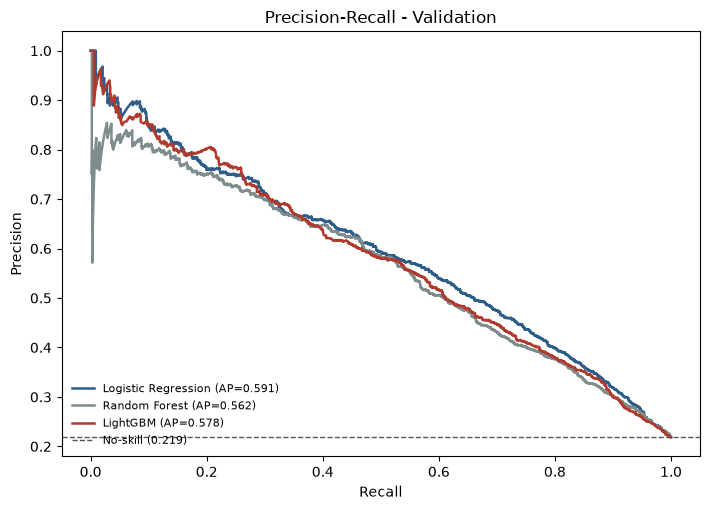

In [5]:
warna = {"Logistic Regression": "#2f5d8a", "Random Forest": "#7f8c8d", "LightGBM": "#b03a2e"}
fig, ax = plt.subplots(figsize=(7.2, 5.2))
for nama in urutan:
    presisi, recall, _ = precision_recall_curve(y_valid, terbaik[nama]["proba"])
    ax.plot(recall, presisi, color=warna[nama], linewidth=1.8,
            label=f"{nama} (AP={terbaik[nama]['pr_auc']:.3f})")
ax.axhline(y_valid.mean(), color="#555555", linestyle="--", linewidth=1,
           label=f"No-skill ({y_valid.mean():.3f})")
ax.set_title("Precision-Recall - Validation")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_pr_curves_models.png", dpi=160, bbox_inches="tight")
plt.show()

## Efek bobot kelas

Penanganan imbalance bisa mengubah kalibrasi probabilitas, jadi dicatat terpisah.

In [6]:
def berbobot(param):
    return param.get("class_weight") is not None or float(param.get("scale_pos_weight", 1)) != 1.0


for nama in urutan:
    kandidat = [h for h in hasil_grid if h["nama"] == nama]
    tanpa = max((h for h in kandidat if not berbobot(h["param"])), key=lambda h: h["pr_auc"])
    dengan = max((h for h in kandidat if berbobot(h["param"])), key=lambda h: h["pr_auc"])
    selisih_bobot = dengan["pr_auc"] - tanpa["pr_auc"]
    arah = "menaikkan" if selisih_bobot > 0 else "menurunkan"
    print(
        f"{nama}: tanpa bobot {tanpa['pr_auc']:.4f}; dengan bobot {dengan['pr_auc']:.4f}; "
        f"bobot {arah} PR-AUC {abs(selisih_bobot):.4f}"
    )

Logistic Regression: tanpa bobot 0.5907; dengan bobot 0.5913; bobot menaikkan PR-AUC 0.0006
Random Forest: tanpa bobot 0.5624; dengan bobot 0.5598; bobot menurunkan PR-AUC 0.0026
LightGBM: tanpa bobot 0.5785; dengan bobot 0.5441; bobot menurunkan PR-AUC 0.0344


## Pemilihan model final

PR-AUC validation dipakai. Jika keunggulan model kompleks kurang dari 0,01,
model lebih sederhana dipilih agar mudah dijelaskan.

In [7]:
baseline = terbaik["Logistic Regression"]
paling_tinggi = max([terbaik[nama] for nama in urutan], key=lambda h: h["pr_auc"])
selisih = paling_tinggi["pr_auc"] - baseline["pr_auc"]

if paling_tinggi["nama"] == "Logistic Regression" or selisih < 0.01:
    pilihan = baseline
    alasan = (
        "Model kompleks tidak memberi kenaikan PR-AUC yang bermakna, jadi regresi "
        "logistik dipilih karena lebih mudah dijelaskan dan lebih stabil."
    )
else:
    pilihan = paling_tinggi
    alasan = f"Kenaikan PR-AUC {selisih:.4f} cukup bermakna dibanding baseline."

print("Model final:", pilihan["nama"])
print("Alasan:", alasan)
print(f"PR-AUC validation: {pilihan['pr_auc']:.4f}")
print(f"ROC-AUC validation: {pilihan['roc_auc']:.4f}")

if paling_tinggi["nama"] != "Logistic Regression" and paling_tinggi["pr_auc"] <= baseline["pr_auc"]:
    print(
        "Catatan jujur: model kompleks tidak mengalahkan baseline. Data sintetik ini "
        "memiliki pola relatif sederhana dan tuning sengaja dibatasi."
    )

versi_final = (
    "lag-logreg-v1"
    if pilihan["nama"] == "Logistic Regression"
    else "lag-lightgbm-v1"
    if pilihan["nama"] == "LightGBM"
    else "lag-rf-v1"
)

Model final: Logistic Regression
Alasan: Model kompleks tidak memberi kenaikan PR-AUC yang bermakna, jadi regresi logistik dipilih karena lebih mudah dijelaskan dan lebih stabil.
PR-AUC validation: 0.5913
ROC-AUC validation: 0.8111


## Simpan model final

Model final dan metadata ditimpa di sini supaya notebook 05 memakai model yang
benar-benar dipilih. Test belum disentuh.

In [8]:
metadata_path = ROOT / "artifacts" / "metadata.json"
metadata = json.loads(metadata_path.read_text(encoding="utf-8"))

metadata.update(
    {
        "model_version": versi_final,
        "tipe_model": f"{pilihan['nama']} dengan build_features (tanpa volume_hub_hari)",
        "tanggal_latih": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S"),
        "feature_builder": "build_features_v1",
        "fitur_masukan": FEATURE_COLUMNS_V1,
        "fitur_dikeluarkan": ["volume_hub_hari", "flag_volume_ekstrem"],
        "pemilihan_model": alasan,
        "thresholds": {"kabari_pelanggan": 0.09, "prioritaskan": 0.30},
        "threshold_status": "placeholder; akan dikunci di notebook 05",
        "metrics": {
            "validation": {
                "pr_auc": float(pilihan["pr_auc"]),
                "roc_auc": float(pilihan["roc_auc"]),
                "perbandingan": {
                    nama: {
                        "pr_auc": float(terbaik[nama]["pr_auc"]),
                        "roc_auc": float(terbaik[nama]["roc_auc"]),
                    }
                    for nama in urutan
                },
                "ablasi_leaky": {"model": "leaky, not deployed", "pr_auc": float(pr_leaky)},
            },
            "test": None,
        },
        "test_disentuh": False,
    }
)

joblib.dump(pilihan["pipeline"], ROOT / "artifacts" / "model.joblib")
joblib.dump(pilihan["pipeline"], ROOT / "artifacts" / "model_base.joblib")
metadata["model_base_file"] = "artifacts/model_base.joblib"
metadata["model_params"] = {k: v for k, v in pilihan["param"].items()}
metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print("Model final tersimpan:", versi_final)

Model final tersimpan: lag-logreg-v1


Data test April-Juni 2026 tidak dibuka, tidak diprediksi, dan tidak dipakai untuk
memilih model.